# 03 – Xử lý dữ liệu với Apache Spark RDD

Notebook của **Thành viên C (Nguyễn Thị Yến Vy – 2001231068)**, gồm 4 phần theo kế hoạch nhóm:

- **A. Khởi tạo môi trường và thao tác cơ bản trên RDD:** `parallelize`, `glom`, `map`, `filter`, `flatMap`, `reduce`, `count`, `take`, `collect`, phân biệt *Transformation* và *Action*.
- **B. Đếm số phim theo thể loại bằng RDD:** đọc bảng `movie` từ Parquet, chuyển sang RDD, tách thể loại, đếm với `reduceByKey`, sắp xếp với `sortBy`, xuất `results/genre_count_C.csv` và vẽ biểu đồ.
- **C. Word Count trên tập `tag`:** xử lý `tag` từ Parquet bằng RDD và minh họa đọc file văn bản thô bằng `sc.textFile`.
- **D. Chuyển đổi RDD ↔ DataFrame, đối chiếu với B & so sánh hiệu năng:** dùng `toDF`, kiểm tra chéo với `results/genre_count_B.csv`, đo thời gian chạy giữa RDD và DataFrame.

**Lưu ý cấu hình:** Chạy trên máy cá nhân **8 GB RAM** nên cell khởi tạo đặt `.master("local[2]")` và `spark.driver.memory = "2g"` theo quy ước nhóm. Đặt `SIZE = "full"` để lấy số liệu cuối (lưu ý hai bảng `movie` và `tag` ở bản `sample` và `full` đều chứa đầy đủ dữ liệu).

## A. Khởi tạo môi trường và thao tác cơ bản trên RDD

### A.1. Khởi tạo SparkSession

Sử dụng cell khởi tạo chung của nhóm (chỉ chỉnh `SIZE = "full"` và cấu hình bộ nhớ cho máy 8 GB).

In [1]:
# ANH: 03_01 | Khởi tạo SparkSession và SparkContext (cấu hình máy 8 GB)
import os
import time
from operator import add
import pandas as pd
from pyspark.sql import SparkSession
from pyspark.sql import functions as F

# "sample" khi viết code, đổi thành "full" khi chạy số liệu cuối
SIZE = "full"
CSV  = "/home/jovyan/work/data/ml-20m"                    # CSV gốc (dùng để minh họa sc.textFile)
DATA = f"/home/jovyan/work/data/ml-20m-parquet/{SIZE}"    # Parquet: B, C đọc từ đây

spark = (SparkSession.builder
         .appName("BigDataLab")
         .master("local[2]")                    # máy 8GB: "local[2]"
         .config("spark.driver.memory", "2g")   # máy 8GB: "2g"
         .config("spark.sql.shuffle.partitions", "8")
         .getOrCreate())
sc = spark.sparkContext
sc.setLogLevel("WARN")

print("Spark version:", spark.version)
print("Số luồng song song:", sc.defaultParallelism)
print("Thư mục dữ liệu DATA:", DATA)

Spark version: 4.2.0
Số luồng song song: 2
Thư mục dữ liệu DATA: /home/jovyan/work/data/ml-20m-parquet/full


### A.2. Khởi tạo RDD từ collection (`parallelize`) và kiểm tra phân vùng (`glom`)

`sc.parallelize(data, numSlices)` phân tán một collection Python thành RDD chia làm nhiều partition. Hàm `glom()` gom các phần tử trong từng partition thành một danh sách để quan sát cách Spark chia dữ liệu.

In [2]:
# ANH: 03_02 | Khởi tạo RDD với parallelize và xem các partition (glom)
nums = sc.parallelize(range(1, 21), 4)
print("Số partition:", nums.getNumPartitions())
for idx, part in enumerate(nums.glom().collect()):
    print(f"  Partition {idx}: {part}")

Số partition: 4


  Partition 0: [1, 2, 3, 4, 5]
  Partition 1: [6, 7, 8, 9, 10]
  Partition 2: [11, 12, 13, 14, 15]
  Partition 3: [16, 17, 18, 19, 20]


### A.3. Thao tác Transformation và Action trên RDD

- **Transformation** (`map`, `filter`, `flatMap`): chỉ mô tả phép biến đổi trên RDD và trả về RDD mới, **chưa thực thi ngay** (lazy evaluation).
- **Action** (`collect`, `reduce`, `count`, `take`): kích hoạt Spark thực sự chạy các bước tính toán và trả kết quả về Driver.

In [3]:
# ANH: 03_03 | Transformation (map, filter, flatMap) và Action (collect, reduce, count, take)
t0 = time.perf_counter()
sq = nums.map(lambda x: x * x)            # transformation: bình phương từng phần tử
even = sq.filter(lambda x: x % 2 == 0)    # transformation: lọc số chẵn
t_trans = time.perf_counter() - t0

t1 = time.perf_counter()
even_list = even.collect()                # action: thực thi DAG và thu kết quả
t_act = time.perf_counter() - t1

print(f"Thời gian tạo Transformation: {t_trans:.5f} s (chưa tính toán)")
print(f"Thời gian gọi Action collect: {t_act:.5f} s")
print("Bình phương chẵn (even.collect):", even_list)
print("Tổng các số 1..20 (reduce):", nums.reduce(lambda a, b: a + b))
print("Số phần tử (count):", nums.count())
print("5 phần tử đầu (take):", nums.take(5))

words = sc.parallelize(["spark rdd", "big data spark"])
print("Tách từ bằng flatMap:", words.flatMap(lambda s: s.split()).collect())

Thời gian tạo Transformation: 0.00012 s (chưa tính toán)
Thời gian gọi Action collect: 0.16816 s
Bình phương chẵn (even.collect): [4, 16, 36, 64, 100, 144, 196, 256, 324, 400]


Tổng các số 1..20 (reduce): 210


Số phần tử (count): 20


5 phần tử đầu (take): [1, 2, 3, 4, 5]
Tách từ bằng flatMap: ['spark', 'rdd', 'big', 'data', 'spark']


## B. Đếm số phim theo thể loại bằng RDD

Đọc bảng `movie` từ Parquet (`27,278` phim), chuyển sang RDD (`movies_df.rdd`), tách chuỗi `genres` theo ký tự `|` bằng `flatMap`, gán cặp `(genre, 1)` với `map`, cộng dồn theo khóa bằng `reduceByKey(add)` và sắp xếp giảm dần với `sortBy`. Kết quả được lưu vào `results/genre_count_C.csv` để đối chiếu với Thành viên B.

In [4]:
# ANH: 03_04 | Đếm số phim theo thể loại bằng RDD và lưu genre_count_C.csv
t0 = time.perf_counter()
movies_df = spark.read.parquet(f"{DATA}/movie")
movies_rdd = movies_df.rdd                 # DataFrame -> RDD of Row

genre_count = (movies_rdd
               .flatMap(lambda r: r.genres.split("|"))
               .map(lambda g: (g, 1))
               .reduceByKey(add)
               .sortBy(lambda kv: -kv[1]))

genre_rows = genre_count.collect()
t_genre_rdd = time.perf_counter() - t0

total_movies = movies_df.count()
total_genre_tags = sum(c for _, c in genre_rows)

os.makedirs("/home/jovyan/work/results", exist_ok=True)
out_c_path = "/home/jovyan/work/results/genre_count_C.csv"
pd.DataFrame(genre_rows, columns=["genre", "count"]).to_csv(out_c_path, index=False)

print(f"Thời gian chạy RDD: {t_genre_rdd:.3f} s")
print(f"Tổng số phim: {total_movies:,} | Tổng lượt gắn thể loại: {total_genre_tags:,} | Số nhóm thể loại: {len(genre_rows)}")
print()
print(f"{'STT':>3}  {'Thể loại':<20} {'Số phim':>10} {'Tỉ lệ / phim':>13}")
print("-" * 52)
for idx, (g, c) in enumerate(genre_rows, 1):
    print(f"{idx:>3}  {g:<20} {c:>10,} {c / total_movies * 100:>12.2f}%")
print()
print("Đã lưu:", out_c_path)

Thời gian chạy RDD: 3.602 s
Tổng số phim: 27,278 | Tổng lượt gắn thể loại: 54,406 | Số nhóm thể loại: 20

STT  Thể loại                Số phim  Tỉ lệ / phim
----------------------------------------------------
  1  Drama                    13,344        48.92%
  2  Comedy                    8,374        30.70%
  3  Thriller                  4,178        15.32%
  4  Romance                   4,127        15.13%
  5  Action                    3,520        12.90%
  6  Crime                     2,939        10.77%
  7  Horror                    2,611         9.57%
  8  Documentary               2,471         9.06%
  9  Adventure                 2,329         8.54%
 10  Sci-Fi                    1,743         6.39%
 11  Mystery                   1,514         5.55%
 12  Fantasy                   1,412         5.18%
 13  War                       1,194         4.38%
 14  Children                  1,139         4.18%
 15  Musical                   1,036         3.80%
 16  Animation           

### B.1. Trực quan hóa số lượng phim theo thể loại

Vẽ biểu đồ cột ngang giúp quan sát nhanh các thể loại phổ biến nhất trong MovieLens 20M (lưu ý một phim có thể thuộc nhiều thể loại cùng lúc, và có 246 phim gắn nhãn `(no genres listed)`).

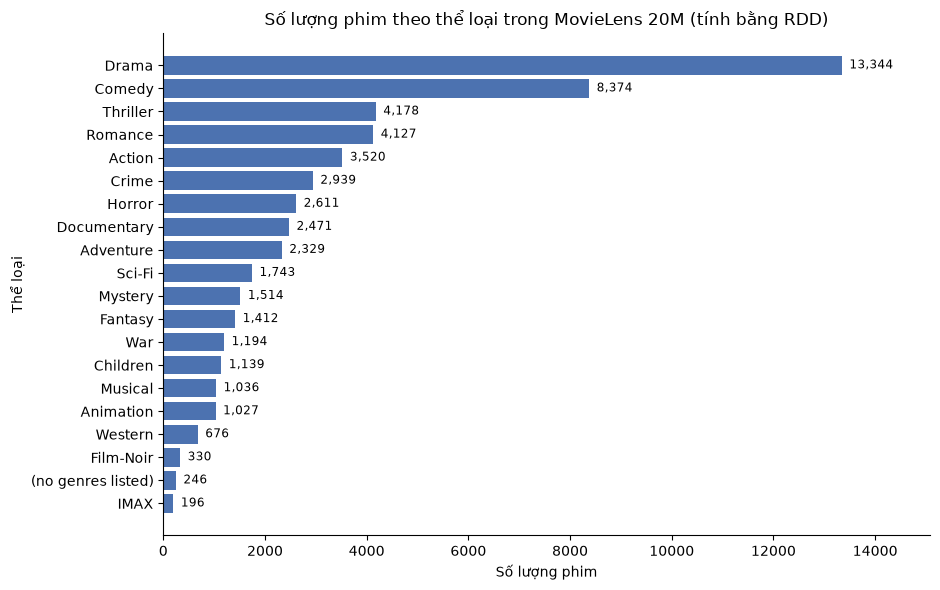

In [5]:
# ANH: 03_05 | Biểu đồ số lượng phim theo thể loại (RDD)
import matplotlib.pyplot as plt

df_plot = pd.DataFrame(genre_rows, columns=["genre", "count"]).sort_values("count", ascending=True)
fig, ax = plt.subplots(figsize=(9.5, 6))
bars = ax.barh(df_plot["genre"], df_plot["count"], color="#4C72B0")
for bar, val in zip(bars, df_plot["count"]):
    ax.text(val + 150, bar.get_y() + bar.get_height() / 2, f"{val:,}", va="center", fontsize=8.5)
ax.set_xlim(0, df_plot["count"].max() * 1.13)
ax.set_title("Số lượng phim theo thể loại trong MovieLens 20M (tính bằng RDD)")
ax.set_xlabel("Số lượng phim")
ax.set_ylabel("Thể loại")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

## C. Word Count trên dữ liệu `tag`

### C.1. Word Count trên bảng `tag` (Parquet → RDD)

Đọc `465,564` lượt gắn tag từ Parquet, chuyển mỗi dòng `tag` sang chữ thường (`lower()`), tách từ theo khoảng trắng (`split()`), sau đó đếm tần suất bằng mẫu kinh điển `flatMap → map → reduceByKey → sortBy`.

In [6]:
# ANH: 03_06 | Word count trên tập tags (Parquet -> RDD)
t0 = time.perf_counter()
tags_df = spark.read.parquet(f"{DATA}/tag")
words_rdd = (tags_df.rdd
             .filter(lambda r: r.tag is not None)
             .flatMap(lambda r: str(r.tag).lower().split()))

word_counts = (words_rdd
               .map(lambda w: (w, 1))
               .reduceByKey(add)
               .sortBy(lambda kv: -kv[1]))

top_words = word_counts.take(20)
total_words = words_rdd.count()
unique_words = word_counts.count()
t_wordcount = time.perf_counter() - t0

print(f"Thời gian Word Count: {t_wordcount:.3f} s")
print(f"Tổng số lượt từ: {total_words:,} | Số từ duy nhất: {unique_words:,}")
print()
print(f"{'Top':>3}  {'Từ khóa':<22} {'Số lần xuất hiện':>18}")
print("-" * 47)
for idx, (w, c) in enumerate(top_words, 1):
    print(f"{idx:>3}  {w:<22} {c:>18,}")

Thời gian Word Count: 5.373 s
Tổng số lượt từ: 779,236 | Số từ duy nhất: 27,793

Top  Từ khóa                  Số lần xuất hiện
-----------------------------------------------
  1  comedy                              7,754
  2  on                                  6,693
  3  a                                   6,513
  4  nudity                              5,990
  5  based                               5,894
  6  ending                              4,962
  7  book                                4,915
  8  dark                                3,919
  9  action                              3,740
 10  story                               3,698
 11  sci-fi                              3,678
 12  oscar                               3,654
 13  war                                 3,353
 14  the                                 3,291
 15  (best                               3,280
 16  atmospheric                         3,174
 17  funny                               3,149
 18  great               

### C.2. Đọc file văn bản thô bằng `sc.textFile`

Khác với `spark.read.parquet` tạo DataFrame có sẵn schema, `sc.textFile(path)` đọc trực tiếp file văn bản thành `RDD[str]` (mỗi phần tử là một dòng thô, gồm cả dòng tiêu đề và dấu ngoặc kép CSV).

In [7]:
# ANH: 03_07 | Đọc file văn bản thô tag.csv bằng sc.textFile
lines = sc.textFile(f"{CSV}/tag.csv")
header = lines.first()
data_lines = lines.filter(lambda line: line != header)

print("Số partition khi đọc tag.csv:", lines.getNumPartitions())
print("Dòng tiêu đề (first):", header)
print("Tổng số dòng (gồm header):", f"{lines.count():,}")
print("Số dòng dữ liệu (bỏ header):", f"{data_lines.count():,}")
print("3 dòng dữ liệu đầu:")
for line in data_lines.take(3):
    print("  ", line)

Số partition khi đọc tag.csv: 2
Dòng tiêu đề (first): "userId","movieId","tag","timestamp"


Tổng số dòng (gồm header): 465,565


Số dòng dữ liệu (bỏ header): 465,564
3 dòng dữ liệu đầu:


   18,4141,"Mark Waters",2009-04-24 18:19:40
   65,208,"dark hero",2013-05-10 01:41:18
   65,353,"dark hero",2013-05-10 01:41:19


## D. Chuyển đổi RDD ↔ DataFrame, đối chiếu với B & so sánh hiệu năng

### D.1. Chuyển đổi RDD sang DataFrame (`toDF`) và đối chiếu với Thành viên B

Sau khi xử lý bằng RDD, có thể chuyển ngược `PairRDD` `(genre, count)` sang DataFrame bằng `.toDF(["genre", "so_phim"])` để tiếp tục dùng Spark SQL / DataFrame API. Dưới đây cũng tự động kiểm tra chéo với `results/genre_count_B.csv` của B nếu file đã có sẵn.

In [8]:
# ANH: 03_08 | Chuyển đổi RDD sang DataFrame và đối chiếu với kết quả của B
genre_df = genre_count.toDF(["genre", "so_phim"])
print("Schema sau khi chuyển RDD -> DataFrame:")
genre_df.printSchema()
genre_df.show(20, truncate=False)

b_path = "/home/jovyan/work/results/genre_count_B.csv"
c_path = "/home/jovyan/work/results/genre_count_C.csv"
if os.path.exists(b_path):
    b_df = pd.read_csv(b_path).set_index("genre")
    c_df = pd.read_csv(c_path).set_index("genre")
    max_diff = (b_df["count"] - c_df["count"]).abs().max()
    print(f"Đối chiếu B và C: chênh lệch lớn nhất = {max_diff} -> {'KHỚP HOÀN TOÀN' if max_diff == 0 else 'CẦN KIỂM TRA'}")
else:
    print("Lưu ý: chưa có results/genre_count_B.csv (Thành viên B chưa đẩy kết quả).")
    print(f"Đã tạo sẵn {c_path} ({len(genre_rows)} thể loại) để đối chiếu ngay khi có file của B.")

Schema sau khi chuyển RDD -> DataFrame:
root
 |-- genre: string (nullable = true)
 |-- so_phim: long (nullable = true)



+------------------+-------+
|genre             |so_phim|
+------------------+-------+
|Drama             |13344  |
|Comedy            |8374   |
|Thriller          |4178   |
|Romance           |4127   |
|Action            |3520   |
|Crime             |2939   |
|Horror            |2611   |
|Documentary       |2471   |
|Adventure         |2329   |
|Sci-Fi            |1743   |
|Mystery           |1514   |
|Fantasy           |1412   |
|War               |1194   |
|Children          |1139   |
|Musical           |1036   |
|Animation         |1027   |
|Western           |676    |
|Film-Noir         |330    |
|(no genres listed)|246    |
|IMAX              |196    |
+------------------+-------+

Lưu ý: chưa có results/genre_count_B.csv (Thành viên B chưa đẩy kết quả).
Đã tạo sẵn /home/jovyan/work/results/genre_count_C.csv (20 thể loại) để đối chiếu ngay khi có file của B.


### D.2. So sánh hiệu năng giữa RDD và DataFrame

Đo lặp 3 lần (lấy trung vị) trên hai quy mô dữ liệu:
1. **Bảng `movie` (27,278 dòng):** đếm số phim theo từng thể loại.
2. **Bảng `tag` (465,564 dòng):** đếm top 10 từ khóa xuất hiện nhiều nhất trong cột `tag`.

In [9]:
# ANH: 03_09 | So sánh thời gian thực thi RDD và DataFrame trên movie và tag
import statistics

def bench(fn, runs=3):
    times = []
    for _ in range(runs):
        t0 = time.perf_counter()
        res = fn()
        times.append(time.perf_counter() - t0)
    return statistics.median(times), res

def movie_rdd():
    return (spark.read.parquet(f"{DATA}/movie").rdd
            .flatMap(lambda r: r.genres.split("|"))
            .map(lambda g: (g, 1))
            .reduceByKey(add)
            .sortBy(lambda kv: -kv[1])
            .collect())

def movie_df():
    return (spark.read.parquet(f"{DATA}/movie")
            .withColumn("genre", F.explode(F.split("genres", r"\|")))
            .groupBy("genre")
            .count()
            .orderBy(F.desc("count"))
            .collect())

def tag_rdd():
    return (spark.read.parquet(f"{DATA}/tag").rdd
            .filter(lambda r: r.tag is not None)
            .flatMap(lambda r: str(r.tag).lower().split())
            .map(lambda w: (w, 1))
            .reduceByKey(add)
            .sortBy(lambda kv: -kv[1])
            .take(10))

def tag_df():
    return (spark.read.parquet(f"{DATA}/tag")
            .filter(F.col("tag").isNotNull())
            .withColumn("word", F.explode(F.split(F.lower(F.col("tag")), r"\s+")))
            .filter(F.col("word") != "")
            .groupBy("word")
            .count()
            .orderBy(F.desc("count"))
            .take(10))

t_m_rdd, r_m_rdd = bench(movie_rdd)
t_m_df,  r_m_df  = bench(movie_df)
t_t_rdd, r_t_rdd = bench(tag_rdd)
t_t_df,  r_t_df  = bench(tag_df)

print("Khớp kết quả movie (RDD vs DataFrame):", dict(r_m_rdd) == {r["genre"]: r["count"] for r in r_m_df})
print("Khớp top 10 tag  (RDD vs DataFrame):", dict(r_t_rdd) == {r["word"]: r["count"] for r in r_t_df})
print()
print(f"{'Bài toán':<32} {'RDD (s)':>10} {'DataFrame (s)':>15} {'Tỉ lệ (RDD/DF)':>16}")
print("-" * 76)
print(f"{'Đếm thể loại movie (27k dòng)':<32} {t_m_rdd:>10.3f} {t_m_df:>15.3f} {t_m_rdd / t_m_df:>15.2f}x")
print(f"{'Word count tag (465k dòng)':<32} {t_t_rdd:>10.3f} {t_t_df:>15.3f} {t_t_rdd / t_t_df:>15.2f}x")

Khớp kết quả movie (RDD vs DataFrame): True
Khớp top 10 tag  (RDD vs DataFrame): True

Bài toán                            RDD (s)   DataFrame (s)   Tỉ lệ (RDD/DF)
----------------------------------------------------------------------------
Đếm thể loại movie (27k dòng)         0.507           0.559            0.91x
Word count tag (465k dòng)            2.670           0.749            3.57x


## Kết luận phần C

- **Các thao tác RDD cốt lõi:** đã thực hành đầy đủ `parallelize`, `glom`, `map`, `filter`, `flatMap`, `reduce`, `reduceByKey`, `sortBy`, `count`, `take`, `collect`, `textFile` và `toDF`.
- **Số phim theo thể loại (từ 27,278 phim):** nhiều nhất là **Drama** (`13,344` phim, `48.92%`), tiếp theo là **Comedy** (`8,374`), **Thriller** (`4,178`), **Romance** (`4,127`), **Action** (`3,520`); ít nhất là **IMAX** (`196` phim), ngoài ra có `246` phim gắn nhãn `(no genres listed)`. Kết quả đã lưu tại `results/genre_count_C.csv`.
- **Word count trên `tag`:** xử lý `465,564` lượt gắn tag (tổng `779,236` lượt từ, `27,793` từ duy nhất sau chuẩn hóa chữ thường).
- **So sánh RDD và DataFrame:** hai cách cho kết quả khớp nhau. Với dữ liệu nhỏ (`movie` 27k dòng), thời gian chạy gần tương đương do chi phí lập kế hoạch Catalyst; nhưng khi tăng lên `tag` (`465k` dòng), DataFrame nhanh hơn rõ rệt nhờ tối ưu trực tiếp trên JVM (Catalyst + Tungsten), còn PySpark RDD phải tuần tự hóa đối tượng qua lại giữa JVM và Python.

In [10]:
spark.stop()